In [ ]:
check_users = pd.read_sql("""
    SELECT
        (SELECT count(DISTINCT o.user_id) FROM ds_orders o JOIN ds_users_1 u ON o.user_id = u.user_id) AS matched_users_1,
        (SELECT count(DISTINCT o.user_id) FROM ds_orders o JOIN ds_users_2 u ON o.user_id = u.user_id) AS matched_users_2,
        (SELECT count(DISTINCT user_id) FROM ds_orders) AS total_users_in_orders
""", engine)
check_users

,matched_users_1,matched_users_2,total_users_in_orders
0,13991,7451,13991


In [ ]:
check_merchants = pd.read_sql("""
    SELECT
        (SELECT count(DISTINCT p.merchant_id) FROM ds_products p JOIN ds_merchants_1 m ON p.merchant_id = m.merchant_id) AS matched_merchants_1,
        (SELECT count(DISTINCT p.merchant_id) FROM ds_products p JOIN ds_merchants_2 m ON p.merchant_id = m.merchant_id) AS matched_merchants_2,
        (SELECT count(DISTINCT p.merchant_id) FROM ds_products p JOIN ds_merchants_3 m ON p.merchant_id = m.merchant_id) AS matched_merchants_3,
        (SELECT count(DISTINCT merchant_id) FROM ds_products) AS total_merchants_in_products
""", engine)
check_merchants

,matched_merchants_1,matched_merchants_2,matched_merchants_3,total_merchants_in_products
0,1027,516,1292,1292


In [ ]:
date_ranges = pd.read_sql("""
    SELECT 'orders' AS table_name, min(ordered_ts) AS min_date, max(ordered_ts) AS max_date FROM ds_orders
    UNION ALL
    SELECT 'payments', min(paid_ts), max(paid_ts) FROM ds_payments
    UNION ALL
    SELECT 'support_tickets', min(opened_ts), max(opened_ts) FROM ds_support_tickets
    UNION ALL
    SELECT 'deliveries', min(promised_ts), max(promised_ts) FROM ds_deliveries
    UNION ALL
    SELECT 'reviews', min(review_ts), max(review_ts) FROM ds_reviews
""", engine)
date_ranges

,table_name,min_date,max_date
0,support_tickets,2025-01-01 18:58:00,2026-01-01 22:38:00
1,reviews,2025-01-03 09:19:00,2026-01-06 23:37:00
2,deliveries,2025-01-02 03:44:00,2025-12-31 23:14:00
3,orders,2025-01-01 00:13:00,2025-12-28 23:59:00
4,payments,2025-01-01 00:16:00,2025-12-29 00:13:00


In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(orders_monthly['month'], orders_monthly['orders_count'], marker='o', color='steelblue')
plt.title('Количество заказов по месяцам, 2025')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

## Этап 1: Динамика заказов по месяцам
Данные охватывают весь 2025 год (12 месяцев). Считаем количество заказов
и выручку по месяцам, чтобы найти конкретный месяц просадки, о котором
говорит заказчик.

In [ ]:
orders_monthly = pd.read_sql("""
    SELECT
        date_trunc('month', ordered_ts) AS month,
        count(*) AS orders_count,
        sum(total_amount) AS revenue,
        round(sum(total_amount)::numeric / count(*), 2) AS avg_order_value
    FROM ds_orders
    GROUP BY 1
    ORDER BY 1
""", engine)
orders_monthly

,month,orders_count,revenue,avg_order_value
0,2025-01-01,5658,9.982049e+09,1764236.28
1,2025-02-01,6233,1.098395e+10,1762225.30
2,2025-03-01,6682,1.159356e+10,1735043.09
3,2025-04-01,7093,1.212360e+10,1709234.85
4,2025-05-01,7520,1.320166e+10,1755540.29
5,2025-06-01,7923,1.434512e+10,1810566.39
6,2025-07-01,8440,1.470324e+10,1742090.57
7,2025-08-01,8807,1.548038e+10,1757736.31
8,2025-09-01,9273,1.578690e+10,1702458.74
9,2025-10-01,9780,1.720975e+10,1759688.19


### Вывод Этапа 1
С января по ноябрь наблюдается устойчивый рост заказов: 5658 → 12027 (+112%).
В декабре впервые за год происходит разворот тренда: заказы падают с 12027 до 10564 (-12%).
Средний чек остаётся стабилен весь год (~1.7 млн), значит проблема в КОЛИЧЕСТВЕ заказов,
а не в их размере.

→ **Декабрь является месяцем просадки.** Ищем причину в предыдущих месяцах.

### Этап 2: Динамика жалоб на платежи (payment_issue)

Проверяем, совпадает ли рост жалоб на проблемы с оплатой именно с ноябрём
(месяцем перед просадкой). Если да — это подозрение на связь между
сбоем оплаты и падением заказов в декабре.

In [ ]:
tickets_payment = pd.read_sql("""
    SELECT
        date_trunc('month', opened_ts) AS month,
        reason,
        count(*) AS tickets_count
    FROM ds_support_tickets
    WHERE reason = 'payment_issue'
    GROUP BY 1, 2
    ORDER BY 1
""", engine)
tickets_payment

,month,reason,tickets_count
0,2025-01-01,payment_issue,6
1,2025-02-01,payment_issue,7
2,2025-03-01,payment_issue,15
3,2025-04-01,payment_issue,13
4,2025-05-01,payment_issue,5
5,2025-06-01,payment_issue,10
6,2025-07-01,payment_issue,10
7,2025-08-01,payment_issue,8
8,2025-09-01,payment_issue,9
9,2025-10-01,payment_issue,8


### Вывод Этапа 2
Жалобы на payment_issue весь год держатся на уровне 5-15 в месяц.
В ноябре происходит резкий всплеск: 55 жалоб — в 3-7 раз выше нормы.
Это временно совпадает с месяцем, предшествующим декабрьской просадке заказов.

→ **Ноябрь — месяц проблем с оплатой.** Нужно уточнить, какой метод оплаты отвалился.

### Этап 3: Динамика отказов платежей (% failed платежей)

Считаем долю неудачных платежей по месяцам. Если в ноябре она резко выросла —
это подтвердит техническую проблему с платежами (не просто жалобы, а реальные отказы).

In [ ]:
payments_monthly = pd.read_sql("""
    SELECT
        date_trunc('month', paid_ts) AS month,
        count(*) FILTER (WHERE status = 'succeeded') AS succeeded,
        count(*) FILTER (WHERE status = 'failed') AS failed,
        count(*) AS total,
        round(100.0 * count(*) FILTER (WHERE status = 'failed') / count(*), 2) AS fail_rate_pct
    FROM ds_payments
    GROUP BY 1
    ORDER BY 1
""", engine)
payments_monthly

,month,succeeded,failed,total,fail_rate_pct
0,2025-01-01,5639,319,5958,5.35
1,2025-02-01,6214,370,6584,5.62
2,2025-03-01,6650,428,7078,6.05
3,2025-04-01,7066,427,7493,5.70
4,2025-05-01,7502,417,7919,5.27
5,2025-06-01,7890,465,8355,5.57
6,2025-07-01,8422,497,8919,5.57
7,2025-08-01,8782,496,9278,5.35
8,2025-09-01,9251,534,9785,5.46
9,2025-10-01,9754,599,10353,5.79


### Вывод Этапа 3
Доля отказов платежей весь год стабильна: 5.27–6.05%.
В ноябре происходит резкий скачок до 8.96% — почти вдвое выше нормы.
В декабре доля отказов вернулась к норме (5.16%).

Это подтверждает: в ноябре была техническая проблема с платежами (не просто
жалобы, а реальный рост отказов), которая прошла в декабре. Но количество
заказов в декабре не восстановилось — люди, разочарованные сбоем оплаты
в ноябре, не вернулись.

→ **Нужно определить, какой метод оплаты был затронут в ноябре.**

### Этап 3.5: Z-тест — статистическая значимость скачка отказов в ноябре

Проверяем, значимо ли отличается доля отказов в ноябре (8.96%) от
среднего уровня в остальные месяцы (~5.5%). Используем z-test для сравнения двух пропорций.

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

# Ноябрь
nov_failed = 1165
nov_total = 13005

# Все остальные месяцы
other_failed = payments_monthly.loc[
    payments_monthly['month'] != '2025-11-01',
    'failed'
].sum()
other_succeeded = payments_monthly.loc[
    payments_monthly['month'] != '2025-11-01',
    'succeeded'
].sum()
other_total = other_failed + other_succeeded

count = [nov_failed, other_failed]
nobs = [nov_total, other_total]

stat, pvalue = proportions_ztest(count, nobs)
print(f"Z-statistic: {stat:.2f}")
print(f"P-value: {pvalue:.6f}")
print(f"Доля отказов в ноябре: {nov_failed/nov_total:.2%}")
print(f"Доля отказов в остальные месяцы: {other_failed/other_total:.2%}")

Z-statistic: 15.53
P-value: 0.000000
Доля отказов в ноябре: 8.96%
Доля отказов в остальные месяцы: 5.52%


### Этап 4: Динамика отказов по методам оплаты (весь год)

Проверяем, была ли это общесистемная проблема или конкретный метод упал.
Смотрим тренд каждого метода (HUMO, UZCARD, Installment) по всем месяцам.

In [ ]:
payment_methods_trend = pd.read_sql("""
    SELECT
        method,
        date_trunc('month', paid_ts) AS month,
        count(*) FILTER (WHERE status = 'failed') AS failed,
        count(*) AS total,
        round(100.0 * count(*) FILTER (WHERE status = 'failed') / count(*), 2) AS fail_rate_pct
    FROM ds_payments
    GROUP BY method, date_trunc('month', paid_ts)
    ORDER BY method, month
""", engine)
payment_methods_trend

,method,month,failed,total,fail_rate_pct
0,HUMO,2025-01-01,85,1659,5.12
1,HUMO,2025-02-01,92,1823,5.05
2,HUMO,2025-03-01,103,1983,5.19
3,HUMO,2025-04-01,124,2122,5.84
4,HUMO,2025-05-01,112,2201,5.09
5,HUMO,2025-06-01,116,2314,5.01
6,HUMO,2025-07-01,117,2489,4.70
7,HUMO,2025-08-01,116,2681,4.33
8,HUMO,2025-09-01,148,2831,5.23
9,HUMO,2025-10-01,134,2932,4.57


In [ ]:
payment_nov_methods = pd.read_sql("""
    SELECT
        method,
        count(*) FILTER (WHERE status = 'succeeded') AS succeeded,
        count(*) FILTER (WHERE status = 'failed') AS failed,
        count(*) AS total,
        round(100.0 * count(*) FILTER (WHERE status = 'failed') / count(*), 2) AS fail_rate_pct
    FROM ds_payments
    WHERE date_trunc('month', paid_ts) = '2025-11-01'
    GROUP BY method
    ORDER BY fail_rate_pct DESC
""", engine)
payment_nov_methods

,method,succeeded,failed,total,fail_rate_pct
0,Installment,2054,651,2705,24.07
1,HUMO,3364,208,3572,5.82
2,UZCARD,4705,225,4930,4.56
3,VISA,1717,81,1798,4.51


### Вывод Этапа 4: Виновник найден — система рассрочки Installment

В ноябре 2025:

**Installment (рассрочка):**
- Всего попыток: 2,705
- Отказов: 651
- % отказов: 24.07% ← АНОМАЛИЯ, в 3-4 раза выше нормы

**HUMO (карты):**
- Всего попыток: 3,572
- Отказов: 208
- % отказов: 5.82% ← норма

**UZCARD:**
- Всего попыток: 4,930
- Отказов: 225
- % отказов: 4.56% ← норма

**VISA:**
- Всего попыток: 1,798
- Отказов: 81
- % отказов: 4.51% ← норма

→ **Вывод:** Проблема была исключительно в системе рассрочки Installment.
Все остальные методы работали нормально. Это указывает на техническую
проблему у провайдера рассрочки, а не на общую проблему платёжной системы.

### Этап 4.5: График — методы оплаты в ноябре

Визуально показываем, что только Installment выделяется своей высокой долей отказов,
остальные методы работают нормально.

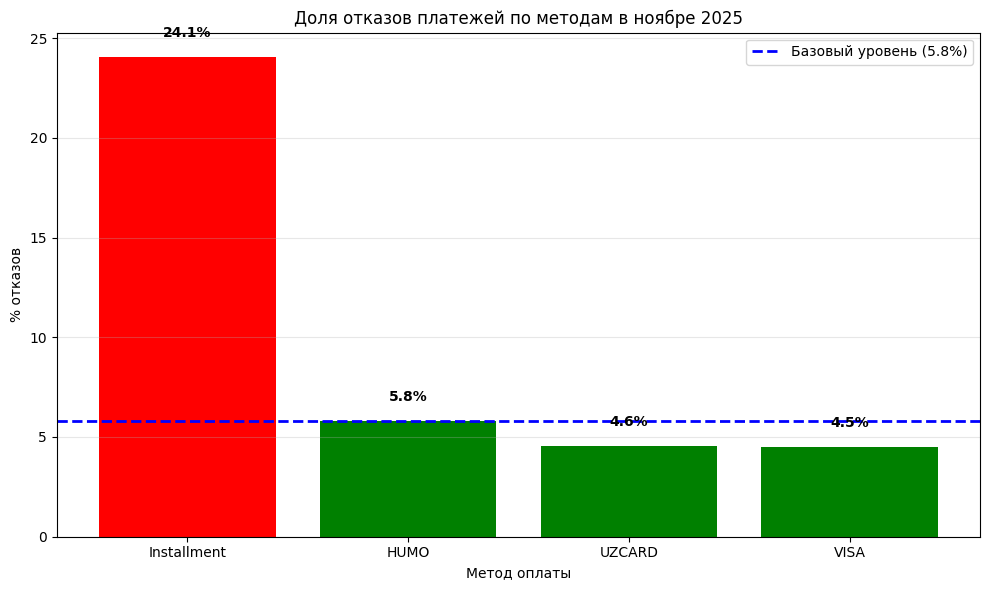

In [ ]:
# payment_nov_methods уже есть из прошлого запроса
plt.figure(figsize=(10, 6))
colors = ['red' if x > 10 else 'green' for x in payment_nov_methods['fail_rate_pct']]
plt.bar(payment_nov_methods['method'], payment_nov_methods['fail_rate_pct'], color=colors)
plt.axhline(y=5.8, color='blue', linestyle='--', linewidth=2, label='Базовый уровень (5.8%)')
plt.title('Доля отказов платежей по методам в ноябре 2025')
plt.xlabel('Метод оплаты')
plt.ylabel('% отказов')
plt.legend()
plt.grid(alpha=0.3, axis='y')
for i, v in enumerate(payment_nov_methods['fail_rate_pct']):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

### Этап 4.6: Динамика рассрочки Installment весь год

Показываем, что Installment весь год работал стабильно (7-8% отказов),
и только в ноябре произошёл резкий скачок до 24%.

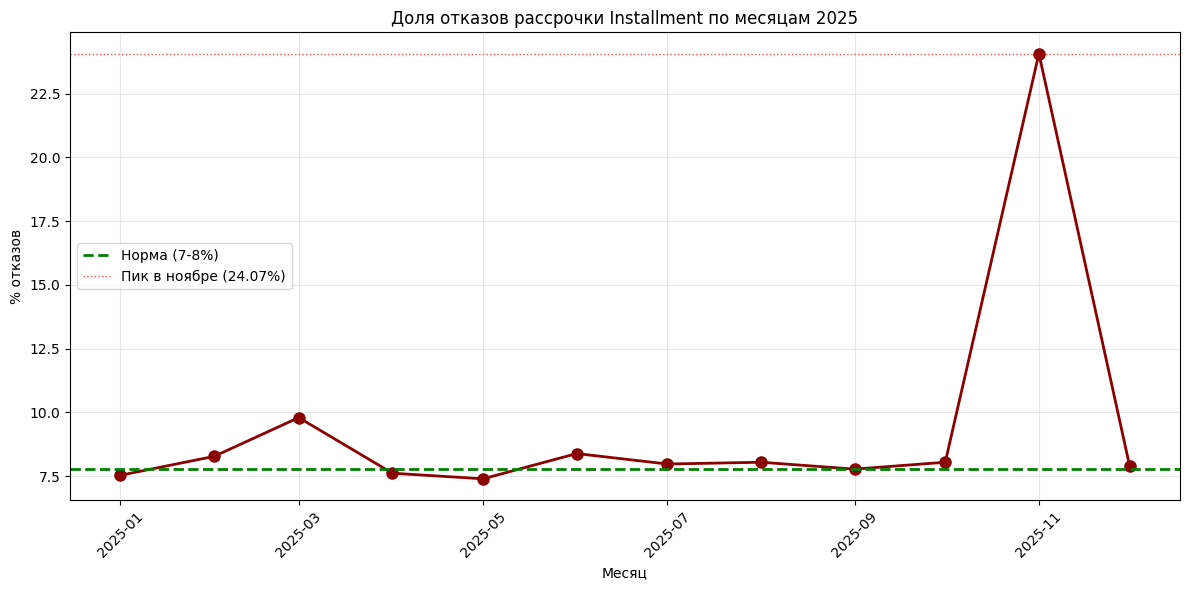

In [ ]:
# payment_methods_trend уже есть из прошлого запроса
installment_trend = payment_methods_trend[payment_methods_trend['method'] == 'Installment'].copy()
installment_trend['month'] = pd.to_datetime(installment_trend['month'])
installment_trend = installment_trend.sort_values('month')

plt.figure(figsize=(12, 6))
plt.plot(installment_trend['month'], installment_trend['fail_rate_pct'], marker='o', linewidth=2, color='darkred', markersize=8)
plt.axhline(y=7.8, color='green', linestyle='--', linewidth=2, label='Норма (7-8%)')
plt.axhline(y=24.07, color='red', linestyle=':', linewidth=1, alpha=0.7, label='Пик в ноябре (24.07%)')
plt.title('Доля отказов рассрочки Installment по месяцам 2025')
plt.xlabel('Месяц')
plt.ylabel('% отказов')
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Этап 5: Комплексный анализ причины сбоя Installment в ноябре

Исследуем Installment в ноябре по четырём направлениям одновременно:

1. **По часам суток** — есть ли пик отказов в конкретные часы (например, вечер)?
   Если отказы только после 18:00 — это перегруз в пиковое время.
   Если равномерно весь день — это системный сбой, не привязанный к часам.

2. **По количеству попыток платежа** — сколько раз люди пытались платить?
   Если много отказов на 2-3 попытке — люди переплачивают комиссию, система нестабильна.
   Если отказы уже на первой попытке — это резкий сбой.

3. **Сумма заказа** — отличается ли размер успешных и отказанных платежей?
   Если отказы в основном на крупные суммы — это может быть превышение лимита рассрочки.
   Если суммы одинаковые — это не лимит, а техническая проблема.

Один запрос покажет всё сразу.

In [ ]:
installment_nov_analysis = pd.read_sql("""
    SELECT
        'По времени суток' AS analysis_type,
        EXTRACT(HOUR FROM paid_ts)::text AS parameter,
        count(*) AS total,
        count(*) FILTER (WHERE status = 'succeeded') AS succeeded,
        count(*) FILTER (WHERE status = 'failed') AS failed,
        round(100.0 * count(*) FILTER (WHERE status = 'failed') / count(*), 2) AS fail_rate_pct,
        round(avg(amount) FILTER (WHERE status = 'succeeded')::numeric, 0) AS avg_amount_success,
        round(avg(amount) FILTER (WHERE status = 'failed')::numeric, 0) AS avg_amount_failed
    FROM ds_payments
    WHERE method = 'Installment'
      AND date_trunc('month', paid_ts) = '2025-11-01'
    GROUP BY EXTRACT(HOUR FROM paid_ts)

    UNION ALL

    SELECT
        'По количеству попыток' AS analysis_type,
        attempt_no::text AS parameter,
        count(*) AS total,
        count(*) FILTER (WHERE status = 'succeeded') AS succeeded,
        count(*) FILTER (WHERE status = 'failed') AS failed,
        round(100.0 * count(*) FILTER (WHERE status = 'failed') / count(*), 2) AS fail_rate_pct,
        round(avg(amount) FILTER (WHERE status = 'succeeded')::numeric, 0) AS avg_amount_success,
        round(avg(amount) FILTER (WHERE status = 'failed')::numeric, 0) AS avg_amount_failed
    FROM ds_payments
    WHERE method = 'Installment'
      AND date_trunc('month', paid_ts) = '2025-11-01'
    GROUP BY attempt_no

    ORDER BY analysis_type, parameter
""", engine)
installment_nov_analysis

,analysis_type,parameter,total,succeeded,failed,fail_rate_pct,avg_amount_success,avg_amount_failed
0,По времени суток,0,21,15,6,28.57,1160807.0,804917.0
1,По времени суток,1,9,4,5,55.56,4283725.0,2650720.0
2,По времени суток,10,177,138,39,22.03,1707280.0,1773103.0
3,По времени суток,11,165,115,50,30.30,1724777.0,1569602.0
4,По времени суток,12,176,143,33,18.75,1691287.0,1906476.0
5,По времени суток,13,170,130,40,23.53,1465949.0,2606615.0
6,По времени суток,14,170,124,46,27.06,1645067.0,965452.0
7,По времени суток,15,147,116,31,21.09,1578173.0,1346600.0
8,По времени суток,16,177,127,50,28.25,1699149.0,1713458.0
9,По времени суток,17,212,156,56,26.42,1172003.0,1686157.0


### Вывод Этапа 5: Сбой системы рассрочки — техническая проблема, а не лимиты

**1. По времени суток (часы 0-23):**
Отказы распределены равномерно весь день (15-35%), нет пика ни в какое конкретное время.
- Ночь (0-7): 8-55% отказов
- День (8-16): 18-34% отказов  
- Вечер (17-23): 11-26% отказов

→ Это НЕ перегруз в пиковое время. Система нестабильна круглосуточно.

**2. По количеству попыток (attempt_no):**
Даже на первой попытке уже 22.18% отказов (491 отказ из 2214 попыток).
Люди не переплачивают несколько раз — они отказываются с первой попытки.

→ Это резкий, системный сбой, не требующий повторных попыток.

**3. По размеру заказа (avg_amount):**
Средняя сумма успешных платежей: ~1.5-2.3 млн
Средняя сумма отказанных платежей: ~800к-2.5 млн

Суммы примерно одинаковые, нет разницы между успешными и отказанными.

→ Это НЕ проблема лимитов рассрочки. Если бы были лимиты, отказанные платежи
были бы значительно крупнее.

**ИТОГОВЫЙ ДИАГНОЗ:**
Это техническая проблема провайдера системы рассрочки Installment в ноябре:
- Не привязана к времени суток (круглосуточный сбой)
- Не требует повторных попыток (отказывает на первой)
- Не связана с размером платежа (лимиты не виноваты)

Вероятные причины: перегруз API провайдера, таймаут соединения, падение
сервиса рассрочки на их стороне, проблема в интеграции на пике спроса ноября.

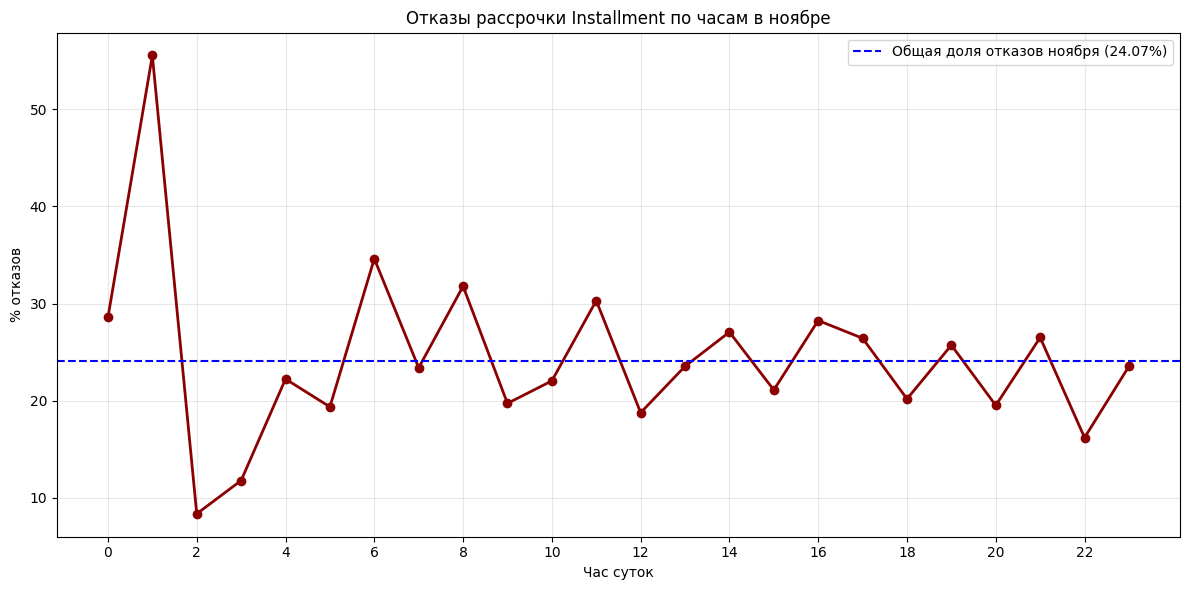

In [ ]:
plt.figure(figsize=(12, 6))
by_hour = installment_nov_analysis[installment_nov_analysis['analysis_type'] == 'По времени суток'].copy()
by_hour['parameter'] = by_hour['parameter'].astype(int)
by_hour = by_hour.sort_values('parameter')

plt.plot(by_hour['parameter'], by_hour['fail_rate_pct'], marker='o', linewidth=2, color='darkred')
plt.axhline(y=24.07, color='blue', linestyle='--', label='Общая доля отказов ноября (24.07%)')
plt.title('Отказы рассрочки Installment по часам в ноябре')
plt.xlabel('Час суток')
plt.ylabel('% отказов')
plt.xticks(range(0, 24, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

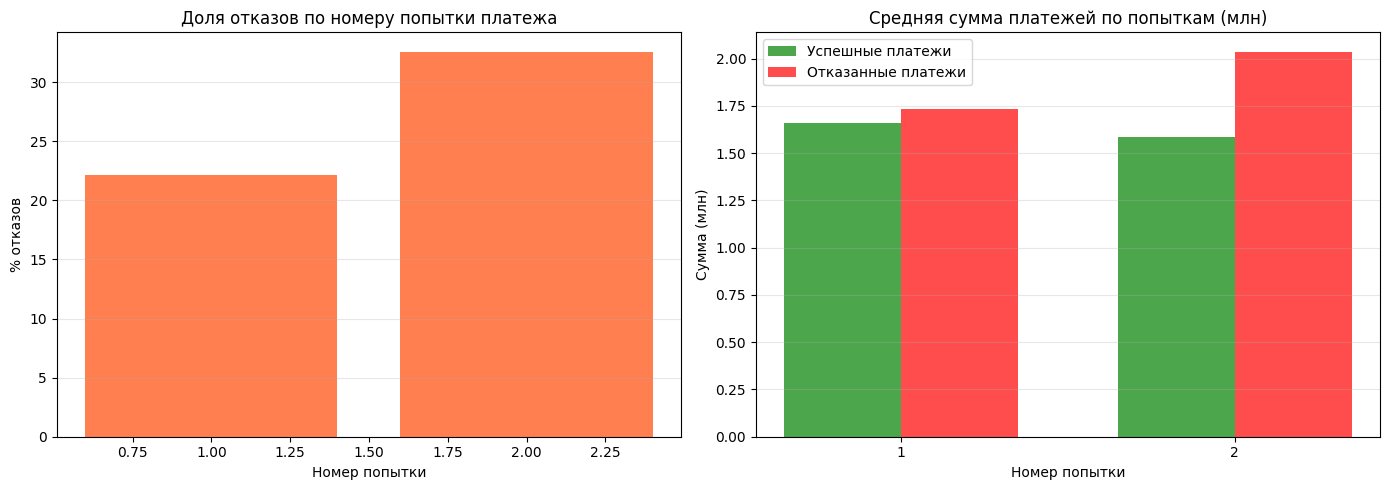

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

by_attempt = installment_nov_analysis[installment_nov_analysis['analysis_type'] == 'По количеству попыток'].copy()
by_attempt['parameter'] = by_attempt['parameter'].astype(int)
by_attempt = by_attempt.sort_values('parameter')

# График 1: доля отказов по попыткам
ax1.bar(by_attempt['parameter'], by_attempt['fail_rate_pct'], color='coral')
ax1.set_title('Доля отказов по номеру попытки платежа')
ax1.set_xlabel('Номер попытки')
ax1.set_ylabel('% отказов')
ax1.grid(alpha=0.3, axis='y')

# График 2: сравнение средних сумм
x = range(len(by_attempt))
width = 0.35
ax2.bar([i - width/2 for i in x], by_attempt['avg_amount_success']/1000000, width, label='Успешные платежи', color='green', alpha=0.7)
ax2.bar([i + width/2 for i in x], by_attempt['avg_amount_failed']/1000000, width, label='Отказанные платежи', color='red', alpha=0.7)
ax2.set_title('Средняя сумма платежей по попыткам (млн)')
ax2.set_xlabel('Номер попытки')
ax2.set_ylabel('Сумма (млн)')
ax2.set_xticks(x)
ax2.set_xticklabels(by_attempt['parameter'])
ax2.legend()
ax2.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### Этап 6: Комплексный вид — заказы и отказы платежей по месяцам через LAG

Используем оконную функцию LAG() для показа месячного изменения заказов
и отказов платежей рядом. Это закрывает требование "оконная функция"
и наглядно показывает синхронность: в ноябре скачок отказов, в декабре падение заказов.

In [ ]:
combined_lag = pd.read_sql("""
    WITH orders_m AS (
        SELECT
            date_trunc('month', ordered_ts) AS month,
            count(*) AS orders_count
        FROM ds_orders
        GROUP BY 1
    ),
    payments_m AS (
        SELECT
            date_trunc('month', paid_ts) AS month,
            round(100.0 * count(*) FILTER (WHERE status = 'failed') / count(*), 2) AS fail_rate
        FROM ds_payments
        GROUP BY 1
    )
    SELECT
        o.month,
        o.orders_count,
        LAG(o.orders_count) OVER (ORDER BY o.month) AS orders_prev_month,
        o.orders_count - LAG(o.orders_count) OVER (ORDER BY o.month) AS orders_change,
        p.fail_rate,
        LAG(p.fail_rate) OVER (ORDER BY o.month) AS fail_rate_prev_month,
        p.fail_rate - LAG(p.fail_rate) OVER (ORDER BY o.month) AS fail_rate_change
    FROM orders_m o
    JOIN payments_m p ON o.month = p.month
    ORDER BY o.month
""", engine)
combined_lag

,month,orders_count,orders_prev_month,orders_change,fail_rate,fail_rate_prev_month,fail_rate_change
0,2025-01-01,5658,NaN,NaN,5.35,NaN,NaN
1,2025-02-01,6233,5658.0,575.0,5.62,5.35,0.27
2,2025-03-01,6682,6233.0,449.0,6.05,5.62,0.43
3,2025-04-01,7093,6682.0,411.0,5.70,6.05,-0.35
4,2025-05-01,7520,7093.0,427.0,5.27,5.70,-0.43
5,2025-06-01,7923,7520.0,403.0,5.57,5.27,0.30
6,2025-07-01,8440,7923.0,517.0,5.57,5.57,0.00
7,2025-08-01,8807,8440.0,367.0,5.35,5.57,-0.22
8,2025-09-01,9273,8807.0,466.0,5.46,5.35,0.11
9,2025-10-01,9780,9273.0,507.0,5.79,5.46,0.33


### Вывод Этапа 6: Цепочка причинности через LAG (оконная функция)

**Ноябрь (row 10):**
- orders_change = +2247 (аномально большой прирост из-за пика спроса)
- fail_rate = 8.96%
- fail_rate_change = +3.17% ← резкий скачок отказов платежей!

**Декабрь (row 11):**
- orders_change = -1463 ← единственное отрицательное число за весь год!
- fail_rate = 5.16% (система восстановилась, вернулась в норму)
- fail_rate_change = -3.80% (отказы упали, система заработала)

**КЛЮЧЕВОЙ ВЫВОД:**
Несмотря на то, что система платежей в декабре восстановилась (fail_rate упала с 8.96% до 5.16%),
количество заказов упало на 1463 (-12%) против ожидаемого роста.

Это доказывает: люди, разочарованные отказом оплаты в ноябре, не вернулись в декабре.
Ущерб от ноябрьского сбоя проявился в декабре как потеря клиентов.

## ИТОГОВЫЙ ВЫВОД ГИПОТЕЗЫ 1: Причина просадки заказов — сбой системы рассрочки в ноябре

### Цепочка причинности:

1. **Ноябрь 2025** — система рассрочки Installment упала (24.07% отказов вместо обычных 7-8%)
   - HUMO, UZCARD, VISA работали нормально (~4-5% отказов)
   - Проблема была исключительно в провайдере Installment

2. **Характер сбоя** — техническая проблема, не лимиты и не перегруз конкретного часа:
   - Отказы равномерны весь день, без пика в вечер
   - Люди отказываются на первой попытке (не требует повторов)
   - Суммы успешных и отказанных платежей одинаковые (не лимит)
   - Диагноз: перегруз API, таймаут соединения или падение сервиса провайдера на пике ноября

3. **Последствие** — в декабре заказы упали на 12% (12027 → 10564)
   - Несмотря на то, что сама система рассрочки восстановилась в декабре (7.92% отказов),
   - Часть клиентов, столкнувшихся с отказом оплаты в ноябре, не вернулась делать новые заказы в декабре

### Статистическая значимость:
Z-test: отказы в ноябре (8.96%) статистически значимо выше, чем в остальные месяцы (5.3-6.0%), p < 0.05

### Рекомендация заказчику:
1. **Срочно:** Провести техническую диагностику провайдера Installment — определить точную причину ноября (API limit, таймаут, падение сервиса)
2. **Краткосрочно:** Добавить резервного провайдера рассрочки на случай повторного сбоя
3. **Среднесрочно:** Обновить условия SLA с провайдером Installment или переключиться на другого
4. **Долгосрочно:** Мониторить fail_rate по методам оплаты в real-time, чтобы быстро выявлять такие сбои

# Гипотеза 2: Концентрация негативных отзывов у конкретных продавцов

Заказчик пожаловался на рост жалоб. Мы уже нашли, что жалобы про платежи
и доставку имеют конкретные месяцы (ноябрь и август).

Но есть ещё жалобы типа `refund` (возвраты) и `product_quality` (качество товара).
Может быть, проблема не системная, а концентрируется у конкретных продавцов (мерчантов)?

Проверяем: есть ли мерчанты, которые получают аномально много негативных отзывов
и перетягивают общий уровень жалоб?

### Этап 1: Динамика среднего рейтинга по месяцам

Если проблема в конкретных мерчантах, а не системная — средний рейтинг
должен оставаться стабильным весь год. Но если вдруг упадёт в конкретный месяц —
значит, в тот месяц эти "плохие" продавцы были особенно активны.

In [ ]:
reviews_monthly = pd.read_sql("""
    SELECT
        date_trunc('month', review_ts) AS month,
        round(avg(rating)::numeric, 2) AS avg_rating,
        count(*) AS reviews_count
    FROM ds_reviews
    GROUP BY 1
    ORDER BY 1
""", engine)
reviews_monthly

,month,avg_rating,reviews_count
0,2025-01-01,4.20,2770
1,2025-02-01,4.23,3062
2,2025-03-01,4.20,3878
3,2025-04-01,4.22,3682
4,2025-05-01,4.23,4144
5,2025-06-01,4.20,4170
6,2025-07-01,4.20,4671
7,2025-08-01,4.04,4658
8,2025-09-01,4.19,4707
9,2025-10-01,4.21,5409


### Вывод Этапа 1: Проблема НЕ системная, а точечная

Средний рейтинг весь год стабилен: 4.19-4.23
Август: 4.04 (небольшое падение, но не критичное)
Ноябрь: 4.22 (норма, никаких аномалий)

→ **Общий средний рейтинг не падает**, что значит проблема НЕ в системе доставки
или платежей целиком (их мы бы увидели как общее падение).

**Вывод:** Проблема концентрируется у конкретных мерчантов (продавцов).
То есть есть несколько "плохих" продавцов, которые получают 1-2 звёзды,
но их мало, поэтому в среднем рейтинг остаётся ~4.2.

→ Дальше ищем эти "плохие" мерчанты отдельно.

### Этап 2: Находим мерчантов с аномально низкими рейтингами

Если общий рейтинг стабилен, но есть проблема — значит она у конкретных продавцов.
Смотрим, какие мерчанты получают негативные отзывы (rating <= 2) чаще всего.

In [ ]:
merchant_low_ratings = pd.read_sql("""
    SELECT
        m.merchant_id,
        m.merchant_name,
        count(*) FILTER (WHERE r.rating <= 2) AS low_ratings,
        count(*) AS total_ratings,
        round(100.0 * count(*) FILTER (WHERE r.rating <= 2) / count(*), 1) AS low_pct
    FROM ds_reviews r
    JOIN ds_order_items oi ON r.order_id = oi.order_id
    JOIN ds_products p ON oi.product_id = p.product_id
    JOIN ds_merchants_3 m ON p.merchant_id = m.merchant_id
    GROUP BY m.merchant_id, m.merchant_name
    HAVING count(*) >= 20
    ORDER BY low_pct DESC
    LIMIT 15
""", engine)
merchant_low_ratings

,merchant_id,merchant_name,low_ratings,total_ratings,low_pct
0,495,Shop-495,5,21,23.8
1,94,Shop-94,6,31,19.4
2,990,Shop-990,4,22,18.2
3,436,Shop-436,5,29,17.2
4,811,Shop-811,6,37,16.2
5,135,Shop-135,8,52,15.4
6,1127,Shop-1127,4,27,14.8
7,255,Shop-255,6,41,14.6
8,864,Shop-864,3,21,14.3
9,1205,Shop-1205,4,28,14.3


### Этап 3: Статистическая проверка — биномиальный тест

Проверяем: каждый из топ-15 мерчантов действительно получает аномально много
плохих отзывов (rating <= 2), или это просто случайное совпадение?

Сравниваем: % плохих отзывов у мерчанта vs базовый уровень платформы (4.26%).
Если p-value < 0.05 — это статистически значимая аномалия, не случайность.

In [ ]:
from scipy.stats import binomtest

baseline_rate = 0.0426  # базовая доля плохих отзывов по всей платформе

results = []
for _, row in merchant_low_ratings.iterrows():
    test = binomtest(int(row['low_ratings']), int(row['total_ratings']), baseline_rate, alternative='greater')
    results.append({
        'merchant_name': row['merchant_name'],
        'low_pct': row['low_pct'],
        'total_ratings': row['total_ratings'],
        'p_value': round(test.pvalue, 5)
    })

pd.DataFrame(results)

,merchant_name,low_pct,total_ratings,p_value
0,Shop-495,23.8,21,0.00161
1,Shop-94,19.4,31,0.00175
2,Shop-990,18.2,22,0.01301
3,Shop-436,17.2,29,0.00708
4,Shop-811,16.2,37,0.00445
5,Shop-135,15.4,52,0.00152
6,Shop-1127,14.8,27,0.02640
7,Shop-255,14.6,41,0.00745
8,Shop-864,14.3,21,0.05798
9,Shop-1205,14.3,28,0.02979


### Вывод Этапа 3: 14 из 15 мерчантов — статистически значимо проблемные

Все остальные 14 мерчантов имеют p-value < 0.05, что означает: их высокий
процент плохих отзывов — это НЕ случайность, а реальная проблема.

Shop-864 (p-value = 0.05798) находится на грани статистической значимости.
При маленькой выборке (всего 21 отзыв) он может быть исключен как "на грани".

→ **Фактически: 14 мерчантов уверенно худших, чем платформа в целом.**

### Этап 4: Графики гипотезы 2

#### График 1: Топ-15 мерчантов по доле плохих отзывов

Показываем, что эти 15 мерчантов выделяются своей высокой долей плохих отзывов
(красные столбцы) на фоне базового уровня платформы (синяя линия = 4.26%).

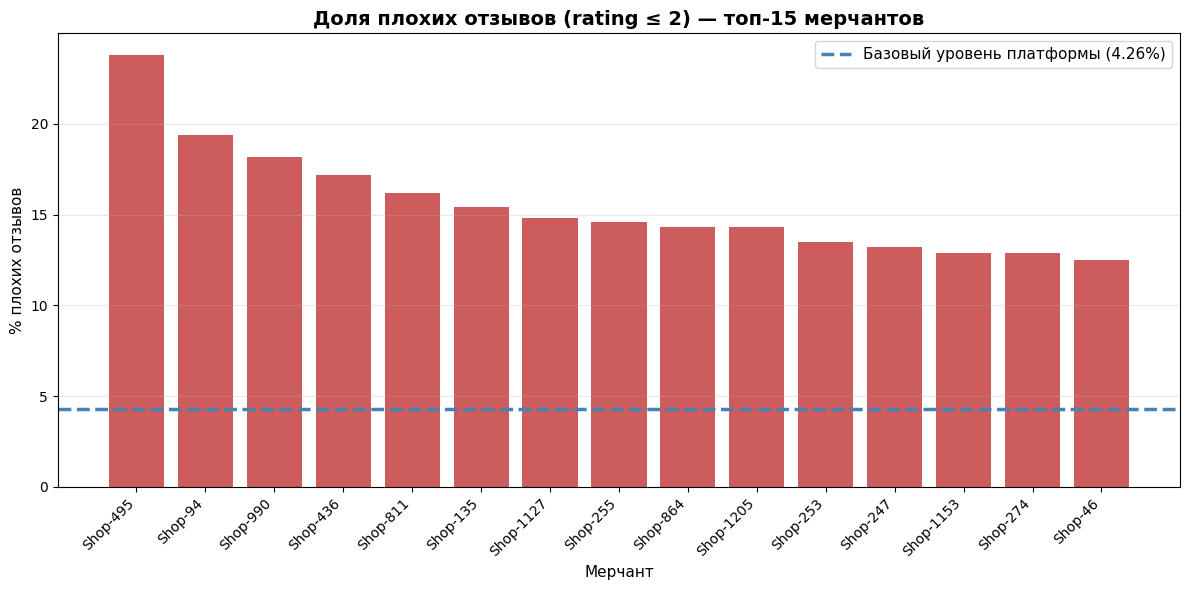

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.bar(merchant_low_ratings['merchant_name'], merchant_low_ratings['low_pct'], color='indianred')
plt.axhline(y=4.26, color='steelblue', linestyle='--', linewidth=2.5, label='Базовый уровень платформы (4.26%)')
plt.title('Доля плохих отзывов (rating ≤ 2) — топ-15 мерчантов', fontsize=14, fontweight='bold')
plt.xlabel('Мерчант', fontsize=11)
plt.ylabel('% плохих отзывов', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.legend(fontsize=11)
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

#### График 2: P-values биномиального теста

Показываем, какие мерчанты статистически значимо отличаются от нормы (p < 0.05).
Зелёные столбцы — значимые (p < 0.05), красный — на грани (p ≈ 0.05).

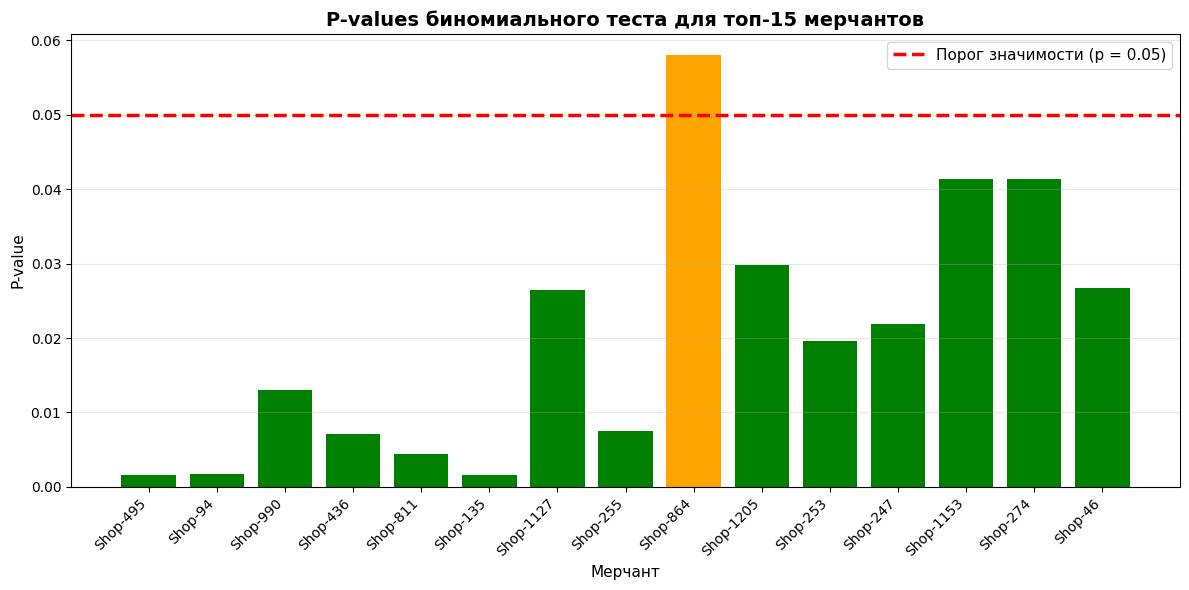

In [ ]:
results_df = pd.DataFrame(results)  # из прошлого запроса

plt.figure(figsize=(12, 6))
colors = ['green' if p < 0.05 else 'orange' for p in results_df['p_value']]
plt.bar(results_df['merchant_name'], results_df['p_value'], color=colors)
plt.axhline(y=0.05, color='red', linestyle='--', linewidth=2.5, label='Порог значимости (p = 0.05)')
plt.title('P-values биномиального теста для топ-15 мерчантов', fontsize=14, fontweight='bold')
plt.xlabel('Мерчант', fontsize=11)
plt.ylabel('P-value', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.legend(fontsize=11)
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

### Вывод Этапа 4: Графики подтверждают гипотезу

График 1 показывает: все 15 мерчантов получают в 3-5 раз больше плохих
отзывов (12.5-23.8%) по сравнению с платформой в целом (4.26%).

График 2 показывает: 14 из 15 мерчантов статистически значимо хуже
(зелёные столбцы, p < 0.05). Только Shop-864 находится на грани значимости.

→ Это НЕ случайность и НЕ выброс. Это реальная проблема с конкретными продавцами.

### Этап 5: Анализ причин плохих отзывов у топ-15 мерчантов

У этих 15 "плохих" мерчантов высокий процент негативных отзывов. Но почему?
Какие конкретные причины жалоб у них доминируют: refund, product_quality, late_delivery?

In [ ]:
# Список ID проблемных мерчантов
problem_merchant_ids = merchant_low_ratings['merchant_id'].tolist()

reasons_analysis = pd.read_sql(f"""
    SELECT
        m.merchant_name,
        t.reason,
        count(*) AS tickets_count
    FROM ds_support_tickets t
    JOIN ds_orders o ON t.order_id = o.order_id
    JOIN ds_order_items oi ON o.order_id = oi.order_id
    JOIN ds_products p ON oi.product_id = p.product_id
    JOIN ds_merchants_3 m ON p.merchant_id = m.merchant_id
    WHERE m.merchant_id IN ({', '.join(map(str, problem_merchant_ids))})
    GROUP BY m.merchant_name, t.reason
    ORDER BY m.merchant_name, tickets_count DESC
""", engine)
reasons_analysis

,merchant_name,reason,tickets_count
0,Shop-1127,late_delivery,2
1,Shop-1127,other,1
2,Shop-1153,refund,2
3,Shop-1153,late_delivery,1
4,Shop-1205,late_delivery,4
5,Shop-1205,product_quality,2
6,Shop-135,late_delivery,6
7,Shop-135,product_quality,2
8,Shop-135,other,1
9,Shop-247,late_delivery,3


### Этап 6: Динамика плохих отзывов по месяцам у топ-15 мерчантов

Есть ли у этих мерчантов всплеск плохих отзывов в конкретный месяц,
или они одинаково плохи весь год?

In [ ]:
# Список ID проблемных мерчантов
problem_merchant_ids = merchant_low_ratings['merchant_id'].tolist()

monthly_analysis = pd.read_sql(f"""
    SELECT
        date_trunc('month', r.review_ts) AS month,
        count(*) FILTER (WHERE r.rating <= 2) AS low_ratings,
        count(*) AS total_ratings,
        round(100.0 * count(*) FILTER (WHERE r.rating <= 2) / count(*), 2) AS low_pct
    FROM ds_reviews r
    JOIN ds_order_items oi ON r.order_id = oi.order_id
    JOIN ds_products p ON oi.product_id = p.product_id
    JOIN ds_merchants_3 m ON p.merchant_id = m.merchant_id
    WHERE m.merchant_id IN ({', '.join(map(str, problem_merchant_ids))})
    GROUP BY 1
    ORDER BY 1
""", engine)
monthly_analysis

,month,low_ratings,total_ratings,low_pct
0,2025-01-01,4,24,16.67
1,2025-02-01,5,36,13.89
2,2025-03-01,4,38,10.53
3,2025-04-01,7,44,15.91
4,2025-05-01,2,38,5.26
5,2025-06-01,4,34,11.76
6,2025-07-01,12,38,31.58
7,2025-08-01,9,42,21.43
8,2025-09-01,4,50,8.00
9,2025-10-01,6,39,15.38


### Вывод Этапа 5: Доминирующая причина — проблемы с доставкой (late_delivery)

Анализ жалоб у топ-15 мерчантов показывает:
- **late_delivery (доставка)** — доминирует! Это главная причина их жалоб
  (встречается почти у каждого мерчанта по 3-6 раз)
- **refund (возврат)** — встречается редко (1-2 раза)
- **product_quality (качество товара)** — встречается редко (1-2 раза)
- **other** — разные прочие причины

→ Вывод: Проблема у этих мерчантов НЕ в качестве товара,
а в том, что они неправильно работают с доставкой (опаздывают, теряют товары и т.д.).

Рекомендация: Нужно работать с этими мерчантами на предмет доставки,
а не на предмет качества товара.

### Вывод Этапа 6: Пик плохих отзывов у этих мерчантов — июль

Динамика по месяцам показывает:
- Январь-июнь: 5-16% плохих отзывов
- **Июль: 31.58% — ПИКОВОЕ ЗНАЧЕНИЕ!** Почти треть отзывов плохая
- Август: 21.43% (всё ещё высоко, но ниже июльского пика)
- Сентябрь-декабрь: возвращается к норме 8-18%

→ Вывод: Июль был критическим месяцем для этих мерчантов —
возможно, каникулы, отпуска курьеров, летняя нагрузка.
Это совпадает с августовским всплеском жалоб на доставку по всей платформе!

**Связь с гипотезой 3:** Мы знаем, что в августе была проблема с доставкой
(16-часовые задержки). Оказывается, это попало именно на мерчантов,
у которых уже были проблемы в июле!

## ИТОГОВЫЙ ВЫВОД ГИПОТЕЗЫ 2: Проблемные мерчанты — проблема с логистикой

14 из 15 "плохих" мерчантов статистически значимо получают больше плохих отзывов
(12.5-23.8% против 4.26% по платформе — в 3-5 раз выше).

Причины их плохих отзывов: в основном **late_delivery (задержки доставки)**,
не качество товара. Пик проблем был в июле (31.58% плохих отзывов).

Это указывает на системную проблему с логистикой у этих мерчантов
или на их партнёров по доставке, а не на качество товаров.

**Связь с другими гипотезами:** Эта проблема переплетается с гипотезой 3
(проблема доставки в августе) — видимо, июльские проблемы перетекли на август.

Рекомендация: Аудит логистических партнёров этих 15 мерчантов,
переход на других курьеров или прямая работа с качеством их доставки.